# **Bootstrap de los modelos finales de la eliminación hacia atrás**

Se comparan los dos modelos finales de la eliminación hacia atrás con red
elástica y AIC:

- **Modelo A**: casos completos (N = 530), paso 3 de `backward_elastic_net.ipynb`.
- **Modelo B**: imputado (N = 669, 20 bases), paso 8 de
  `backward_elastic_net_imputed.ipynb`.

**Parte 1** (principal): coeficientes por MCO de cada modelo con su propia
fórmula, con bootstrap pareado. **Parte 2** (complementaria): estabilidad de la
selección repitiendo la eliminación completa en remuestras.

## *Carga de paquetes y configuración*

In [1]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(gt)
})

# Parche para que las tablas gt se vean en Jupyter (mismo del EDA)
repr_html.gt_tbl <- function(obj, ...) gt::as_raw_html(obj)
repr_markdown.gt_tbl <- function(obj, ...) NULL
repr_latex.gt_tbl <- function(obj, ...) NULL
for (g in c("repr_html", "repr_markdown", "repr_latex")) {
  registerS3method(g, "gt_tbl", get(paste0(g, ".gt_tbl")), envir = asNamespace("repr"))
}

# Las rutas de config.R son relativas a la raíz del proyecto.
if (!file.exists("myst.yml") && file.exists("../myst.yml")) setwd("..")

if (file.exists(".Renviron")) readRenviron(".Renviron")

source("R/config.R")
source("R/data_prep.R")
source("R/moderation_pipeline.R")
source("R/cross_validation.R")   # assign_stratified_folds()
source("R/elastic_net.R")        # build_en_design()
source("R/imputed_pipeline.R")
source("R/backward_en.R")

col_morado <- viridisLite::viridis(10, end = 0.8)[1]
col_verde  <- viridisLite::viridis(10, end = 0.8)[10]

### *Parámetros*

Los resultados del bootstrap se guardan en `outputs/models/`. Si ya existen con
los mismos parámetros se cargan; con `RECALCULAR <- TRUE` se recalculan.

In [2]:
N_BOOT_COEF  <- 2000L   # parte 1
N_BOOT_SEL_A <- 200L    # parte 2, casos completos
N_BOOT_SEL_B <- 100L    # parte 2, imputado
ZERO_SHARE   <- 0.5     # regla de cero del notebook imputado
CORES        <- max(1L, parallel::detectCores() - 2L)
RECALCULAR   <- FALSE

DIR_BOOT <- "outputs/models"
PATH_BOOT_COEF  <- file.path(DIR_BOOT, "bootstrap_coeficientes.rds")
PATH_BOOT_SEL_A <- file.path(DIR_BOOT, "bootstrap_seleccion_cc.rds")
PATH_BOOT_SEL_B <- file.path(DIR_BOOT, "bootstrap_seleccion_mi.rds")

# Carga el resultado guardado si coincide con los parámetros; si no, lo calcula.
en_cache <- function(path, params, calcular) {
  if (!RECALCULAR && file.exists(path)) {
    r <- readRDS(path)
    if (identical(attr(r, "params"), params)) return(r)
  }
  r <- calcular()
  attr(r, "params") <- params
  dir.create(dirname(path), showWarnings = FALSE, recursive = TRUE)
  saveRDS(r, path)
  r
}

## *Datos, preprocesamiento y folds*

Los mismos de los dos notebooks de la eliminación hacia atrás.

In [3]:
# Modelo A: casos completos
model_data <- build_analytic_sample()
design_a   <- build_en_design(model_data)
set.seed(SEED)
foldid_a   <- assign_stratified_folds(model_data[[CV_STRATA_VAR]], EN_INNER_FOLDS)

# Modelo B: 20 bases imputadas
bases     <- load_imputed_datasets()
mi_params <- learn_mi_preprocessing(bases)
designs_b <- map(prepare_mi(bases, mi_params), build_en_design)
set.seed(SEED)
foldid_b  <- assign_stratified_folds(bases[[1]][[CV_STRATA_VAR]], EN_INNER_FOLDS)

cat(sprintf("A: %d casos, %d columnas\n", nrow(design_a$x), ncol(design_a$x)))
cat(sprintf("B: %d bases de %d casos, %d columnas\n",
            length(designs_b), nrow(designs_b[[1]]$x), ncol(designs_b[[1]]$x)))

A: 530 casos, 14 columnas


B: 20 bases de 669 casos, 14 columnas


### *Columnas de los modelos finales*

Se toman del paso de menor AIC guardado por cada notebook y se verifican contra
la lista esperada.

In [4]:
cols_a <- c("Gender_code", "MunicipalitySanto Tomas", "MunicipalitySuan", "SSEMedium-High",
            "EthnicityAfrodescendant", "EthnicityOther", "Family_c", "Friends_c",
            "SigOthers_c", "Gender_code:Friends_c", "Gender_code:SigOthers_c")
cols_b <- c("Gender_code", "SSEMedium-High", "EthnicityAfrodescendant", "EthnicityOther",
            "Family_c", "Friends_c")
cero_a <- c("SigOthers_c", "Gender_code:Friends_c")   # en cero en la red elástica

final_de <- function(path) {
  s <- read_csv(path, show_col_types = FALSE) %>% slice_min(aic, n = 1, with_ties = FALSE)
  list(step = s$step, vars = str_split_1(s$vars, " \\+ "),
       nonzero = if ("nonzero" %in% names(s)) str_split_1(s$nonzero, " \\+ ") else NULL)
}
fin_a <- final_de(PATH_BACKWARD_EN)
fin_b <- final_de(PATH_MI_BACKWARD_EN)

stopifnot(fin_a$step == 3, setequal(fin_a$vars, cols_a),
          setequal(setdiff(fin_a$vars, fin_a$nonzero), cero_a),
          fin_b$step == 8, setequal(fin_b$vars, cols_b),
          all(cols_a %in% colnames(design_a$x)),
          all(cols_b %in% colnames(designs_b[[1]]$x)))

comunes <- intersect(cols_a, cols_b)
solo_a  <- setdiff(cols_a, cols_b)

tibble(Columna = union(cols_a, cols_b)) %>%
  mutate(A = case_when(Columna %in% cero_a ~ "sí (coef. 0 en la red)",
                       Columna %in% cols_a ~ "sí", TRUE ~ ""),
         B = ifelse(Columna %in% cols_b, "sí", "")) %>%
  gt() %>%
  tab_header(title = "Columnas de los modelos finales",
             subtitle = sprintf("A: paso %d · B: paso %d · verificadas", fin_a$step, fin_b$step))

<div id="ytjkzawvrv" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#ytjkzawvrv table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#ytjkzawvrv thead, #ytjkzawvrv tbody, #ytjkzawvrv tfoot, #ytjkzawvrv tr, #ytjkzawvrv td, #ytjkzawvrv th {
  border-style: none;
}

#ytjkzawvrv p {
  margin: 0;
  padding: 0;
}

#ytjkzawvrv .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#ytjkzawvrv .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#ytjkzawvrv .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#ytjkzawvrv .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#ytjkzawvrv .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#ytjkzawvrv .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#ytjkzawvrv .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#ytjkzawvrv .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#ytjkzawvrv .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#ytjkzawvrv .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#ytjkzawvrv .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#ytjkzawvrv .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#ytjkzawvrv .gt_spanner_row {
  border-bottom-style: hidden;
}

#ytjkzawvrv .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

### *ID de estudiante*

Las bases no traen un ID. Como `build_clean_sample()` e `imputacion.ipynb`
conservan el orden de la base cruda, el ID es la fila de la base cruda, con los
mismos filtros de cada una: eliminación por lista para los 530 y estudiantes con
género para los 669. Se verifica que los 530 son un subconjunto de los 669 y que
sus valores coinciden en las 20 bases.

In [5]:
raw <- read_csv(PATH_RAW_DATA, show_col_types = FALSE) %>% mutate(student_id = row_number())

# 669: estudiantes con género (mismo filtro que imputacion.ipynb)
id_b <- raw %>%
  filter(recode_missing_to_na(Gender) %in% FACTOR_LEVELS$Gender) %>%
  pull(student_id)

# 530: mismos pasos de build_clean_sample()
limpio <- raw %>%
  mutate(across(all_of(setdiff(CATEGORICAL_VARS, "SSE")), recode_missing_to_na),
         SSE = collapse_sse(SSE),
         across(all_of(setdiff(CATEGORICAL_VARS, "SSE")),
                ~ factor(.x, levels = FACTOR_LEVELS[[cur_column()]])))
id_a <- limpio %>% drop_na(all_of(MODEL_VARS)) %>% pull(student_id)

fila_a_en_b <- match(id_a, id_b)            # posición de cada caso de A entre los 669
a_de_b      <- match(id_b, id_a)            # fila de A de cada uno de los 669 (NA si no está)

igual <- function(x, y) identical(as.character(x), as.character(y))
chequeos <- tibble(
  Verificación = c("N de A = 530", "N de B = 669", "A es subconjunto de B",
                   "Valores de A = build_clean_sample()",
                   "Género de B = base cruda",
                   "Valores de A iguales en las 20 bases imputadas"),
  Resultado = c(
    length(id_a) == 530, length(id_b) == 669, all(id_a %in% id_b),
    all(map_lgl(MODEL_VARS, ~ igual(limpio[[.x]][id_a], model_data[[.x]]))),
    igual(limpio$Gender[id_b], bases[[1]]$Gender),
    all(map_lgl(bases, function(b)
      all(map_lgl(MODEL_VARS, ~ igual(b[[.x]][fila_a_en_b], model_data[[.x]])))))
  )
)
stopifnot(all(chequeos$Resultado))
chequeos %>%
  mutate(Resultado = ifelse(Resultado, "sí", "no")) %>%
  gt() %>%
  tab_header(title = "Verificación del ID de estudiante")

<div id="itifbundlz" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#itifbundlz table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#itifbundlz thead, #itifbundlz tbody, #itifbundlz tfoot, #itifbundlz tr, #itifbundlz td, #itifbundlz th {
  border-style: none;
}

#itifbundlz p {
  margin: 0;
  padding: 0;
}

#itifbundlz .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#itifbundlz .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#itifbundlz .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#itifbundlz .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#itifbundlz .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#itifbundlz .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#itifbundlz .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#itifbundlz .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#itifbundlz .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#itifbundlz .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#itifbundlz .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#itifbundlz .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#itifbundlz .gt_spanner_row {
  border-bottom-style: hidden;
}

#itifbundlz .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

# **Parte 1. Comparación de coeficientes**

Cada modelo se reajusta por MCO con sus propias columnas (en A se incluyen
`SigOthers_c` y `Gender_code:Friends_c`). No se usan los coeficientes
penalizados de la red elástica.

En A, `Friends_c` y `SigOthers_c` son las pendientes en las mujeres, porque A
incluye sus interacciones con el género (codificación dummy); en B,
`Friends_c` es la pendiente común.

In [6]:
# MCO con intercepto sobre las columnas indicadas: coeficientes y EE (sin intercepto)
ols <- function(x, y) {
  X   <- cbind(`(Intercept)` = 1, x)
  fit <- lm.fit(X, y)
  b   <- fit$coefficients
  s2  <- sum(fit$residuals^2) / (nrow(X) - fit$rank)
  ee  <- rep(NA_real_, length(b))
  ok  <- !is.na(b)
  ee[ok] <- sqrt(diag(s2 * chol2inv(qr.R(fit$qr)[seq_len(fit$rank), seq_len(fit$rank)])))
  tibble(term = colnames(X), estimate = unname(b), std_error = ee)[-1, ]
}

# Estimación puntual
punto_a <- ols(design_a$x[, cols_a], design_a$y)
punto_b <- imap_dfr(designs_b, ~ ols(.x$x[, cols_b], .x$y) %>% mutate(imp = .y)) %>%
  group_by(term) %>%
  summarise(rubin(estimate, std_error), .groups = "drop")

### *Bootstrap pareado*

En cada remuestra se toman los 669 estudiantes con reemplazo, estratificando por
género. A se ajusta con las filas remuestreadas que están entre los 530; B, con
las mismas filas en las 20 bases, promediando los coeficientes entre bases.

In [7]:
# Índices bootstrap estratificados: remuestrea dentro de cada nivel de `estrato`
remuestra <- function(estrato) {
  unlist(lapply(split(seq_along(estrato), estrato),
                function(i) i[sample.int(length(i), replace = TRUE)]), use.names = FALSE)
}

genero_b <- bases[[1]][[GENDER_VAR]]

boot_coef <- en_cache(PATH_BOOT_COEF, list(N_BOOT_COEF, SEED, cols_a, cols_b), function() {
  set.seed(SEED)
  res <- map(seq_len(N_BOOT_COEF), function(r) {
    idx    <- remuestra(genero_b)
    filasA <- a_de_b[idx]
    filasA <- filasA[!is.na(filasA)]
    bA <- ols(design_a$x[filasA, cols_a], design_a$y[filasA])$estimate
    bB <- rowMeans(sapply(designs_b, function(d) ols(d$x[idx, cols_b], d$y[idx])$estimate))
    list(a = bA, b = bB, n_a = length(filasA))
  })
  list(a   = do.call(rbind, map(res, "a")) %>% `colnames<-`(cols_a),
       b   = do.call(rbind, map(res, "b")) %>% `colnames<-`(cols_b),
       n_a = map_int(res, "n_a"))
})
boot_coef$dif <- boot_coef$a[, comunes] - boot_coef$b[, comunes]

cat(sprintf("Remuestras: %d\n", nrow(boot_coef$a)))
cat(sprintf("Casos de A por remuestra: mediana %d (rango %d–%d)\n",
            as.integer(median(boot_coef$n_a)), min(boot_coef$n_a), max(boot_coef$n_a)))
cat(sprintf("Remuestras con algún coeficiente no estimable: A %d, B %d\n",
            sum(!complete.cases(boot_coef$a)), sum(!complete.cases(boot_coef$b))))

Remuestras: 2000


Casos de A por remuestra: mediana 530 (rango 492–567)


Remuestras con algún coeficiente no estimable: A 0, B 0


In [8]:
# IC percentil 95 %
ic <- function(m) {
  tibble(term = colnames(m),
         lo = apply(m, 2, quantile, 0.025, na.rm = TRUE),
         hi = apply(m, 2, quantile, 0.975, na.rm = TRUE))
}
fmt_ic <- function(lo, hi) sprintf("[%.3f, %.3f]", lo, hi)

ic_a   <- punto_a %>% left_join(ic(boot_coef$a), by = "term")
ic_b   <- punto_b %>% left_join(ic(boot_coef$b), by = "term")
ic_dif <- tibble(term = comunes) %>%
  mutate(dif = punto_a$estimate[match(term, punto_a$term)] -
               punto_b$estimate[match(term, punto_b$term)]) %>%
  left_join(ic(boot_coef$dif), by = "term")

### *Tabla 1. Términos comunes*

In [9]:
tibble(term = comunes) %>%
  left_join(ic_a %>% transmute(term, b_a = estimate, ic_a = fmt_ic(lo, hi)), by = "term") %>%
  left_join(ic_b %>% transmute(term, b_b = estimate, ic_b = fmt_ic(lo, hi)), by = "term") %>%
  left_join(ic_dif %>% transmute(term, dif, ic_dif = fmt_ic(lo, hi),
                                 cero = ifelse(lo <= 0 & hi >= 0, "sí", "no")), by = "term") %>%
  gt() %>%
  fmt_number(c(b_a, b_b, dif), decimals = 3) %>%
  tab_spanner("A: casos completos", c(b_a, ic_a)) %>%
  tab_spanner("B: imputado", c(b_b, ic_b)) %>%
  tab_spanner("Diferencia A − B", c(dif, ic_dif, cero)) %>%
  cols_label(term = "Término", b_a = "b", ic_a = "IC 95 %", b_b = "b (Rubin)",
             ic_b = "IC 95 %", dif = "A − B", ic_dif = "IC 95 %", cero = "¿Incluye 0?") %>%
  tab_header(title = "Tabla 1. Coeficientes de los términos comunes",
             subtitle = sprintf("MCO; IC percentil con %d remuestras bootstrap pareadas",
                                nrow(boot_coef$a)))

<div id="akwcnxhvnw" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#akwcnxhvnw table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#akwcnxhvnw thead, #akwcnxhvnw tbody, #akwcnxhvnw tfoot, #akwcnxhvnw tr, #akwcnxhvnw td, #akwcnxhvnw th {
  border-style: none;
}

#akwcnxhvnw p {
  margin: 0;
  padding: 0;
}

#akwcnxhvnw .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#akwcnxhvnw .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#akwcnxhvnw .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#akwcnxhvnw .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#akwcnxhvnw .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#akwcnxhvnw .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#akwcnxhvnw .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#akwcnxhvnw .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#akwcnxhvnw .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#akwcnxhvnw .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#akwcnxhvnw .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#akwcnxhvnw .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#akwcnxhvnw .gt_spanner_row {
  border-bottom-style: hidden;
}

#akwcnxhvnw .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

### *Tabla 2. Términos que solo están en A*

In [10]:
tibble(term = solo_a) %>%
  left_join(ic_a, by = "term") %>%
  transmute(term, estimate, ic = fmt_ic(lo, hi),
            cero = ifelse(lo <= 0 & hi >= 0, "sí: coherente con que B lo retire", "no")) %>%
  gt() %>%
  fmt_number(estimate, decimals = 3) %>%
  cols_label(term = "Término", estimate = "b", ic = "IC 95 %", cero = "¿IC incluye 0?") %>%
  tab_header(title = "Tabla 2. Términos que solo están en el modelo A",
             subtitle = "MCO con los 530 casos; IC percentil bootstrap")

<div id="nzrnmbzurj" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#nzrnmbzurj table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#nzrnmbzurj thead, #nzrnmbzurj tbody, #nzrnmbzurj tfoot, #nzrnmbzurj tr, #nzrnmbzurj td, #nzrnmbzurj th {
  border-style: none;
}

#nzrnmbzurj p {
  margin: 0;
  padding: 0;
}

#nzrnmbzurj .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#nzrnmbzurj .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#nzrnmbzurj .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#nzrnmbzurj .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#nzrnmbzurj .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#nzrnmbzurj .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#nzrnmbzurj .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#nzrnmbzurj .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#nzrnmbzurj .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#nzrnmbzurj .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#nzrnmbzurj .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#nzrnmbzurj .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#nzrnmbzurj .gt_spanner_row {
  border-bottom-style: hidden;
}

#nzrnmbzurj .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

### *Figura 1. Coeficientes de A y B*

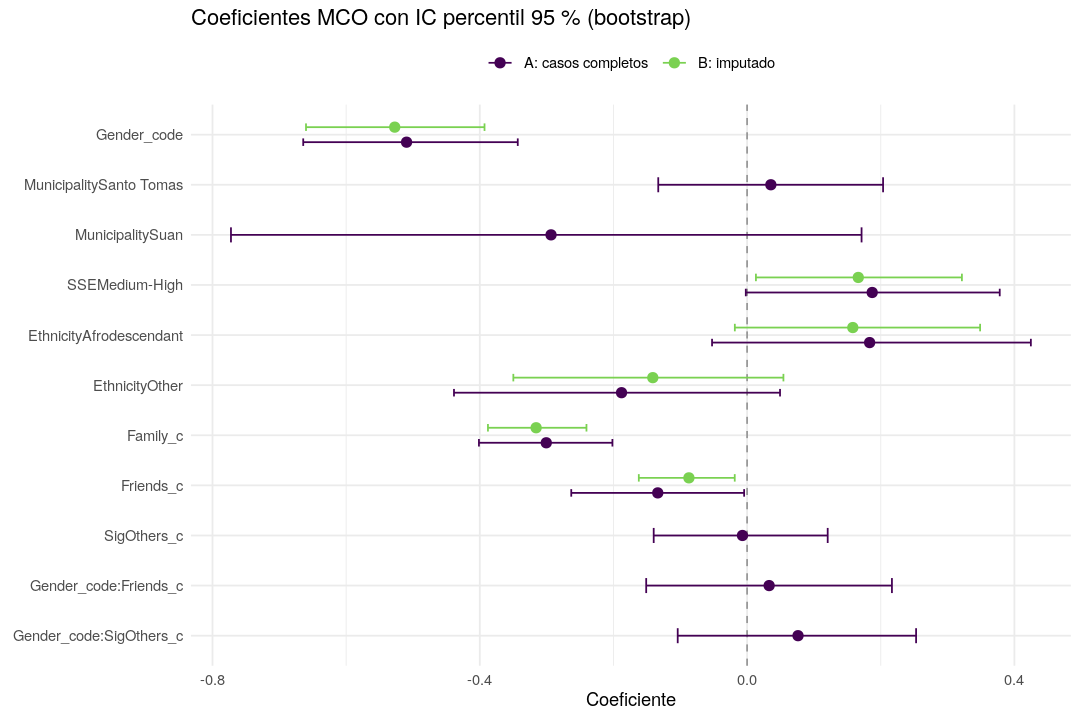

In [11]:
options(repr.plot.width = 9, repr.plot.height = 6)

bind_rows(ic_a %>% mutate(Modelo = "A: casos completos"),
          ic_b %>% mutate(Modelo = "B: imputado")) %>%
  mutate(term = factor(term, levels = rev(union(cols_a, cols_b)))) %>%
  ggplot(aes(x = estimate, y = term, color = Modelo)) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "grey60") +
  geom_errorbar(aes(xmin = lo, xmax = hi), width = 0.3, orientation = "y",
                position = position_dodge(width = 0.6)) +
  geom_point(size = 2.5, position = position_dodge(width = 0.6)) +
  scale_color_manual(values = c(col_morado, col_verde)) +
  labs(title = "Coeficientes MCO con IC percentil 95 % (bootstrap)",
       x = "Coeficiente", y = NULL, color = NULL) +
  theme_minimal() +
  theme(legend.position = "top")

# **Parte 2. Estabilidad de la selección**

Se repite la eliminación hacia atrás completa (red elástica + AIC, eligiendo α
y λ de nuevo en cada paso) en remuestras bootstrap estratificadas por género:
200 de los 530 casos completos y 100 de los 669 imputados, con las mismas filas
en las 20 bases (sin reimputar) y la misma regla del notebook imputado. En cada
remuestra se guarda el modelo del paso de menor AIC.

Cada estudiante conserva su fold de los notebooks originales, de modo que sus
copias en una remuestra quedan en el mismo fold.

In [12]:
columnas <- colnames(design_a$x)

# Casos completos
sel_a <- en_cache(PATH_BOOT_SEL_A, list(N_BOOT_SEL_A, SEED), function() {
  set.seed(SEED + 1)
  idx <- map(seq_len(N_BOOT_SEL_A), ~ remuestra(model_data[[GENDER_VAR]]))
  parallel::mclapply(idx, function(i) {
    res <- backward_en(design_a$x[i, ], design_a$y[i], foldid_a[i], verbose = FALSE)
    k   <- which.min(res$steps$aic)
    fit <- res$fits[[k]]
    coef <- set_names(rep(0, length(columnas)), columnas)
    coef[names(fit$coef)] <- fit$coef
    list(step = res$steps$step[k], vars = fit$vars, coef = coef,
         nonzero = names(fit$coef)[fit$coef != 0])
  }, mc.cores = CORES, mc.preschedule = FALSE)
})
cat(sprintf("Casos completos: %d remuestras, %d fallidas\n",
            length(sel_a), sum(map_lgl(sel_a, inherits, "try-error"))))

Casos completos: 200 remuestras, 0 fallidas


In [13]:
# Imputado: cada remuestra ajusta las 20 bases en paralelo dentro de backward_en_mi()
sel_b <- en_cache(PATH_BOOT_SEL_B, list(N_BOOT_SEL_B, SEED, ZERO_SHARE), function() {
  set.seed(SEED + 2)
  idx <- map(seq_len(N_BOOT_SEL_B), ~ remuestra(genero_b))
  map(seq_along(idx), function(r) {
    i   <- idx[[r]]
    des <- map(designs_b, ~ list(x = .x$x[i, ], y = .x$y[i]))
    res <- backward_en_mi(des, foldid_b[i], zero_share = ZERO_SHARE, cores = CORES,
                          verbose = FALSE)
    k   <- which.min(res$steps$aic)
    fit <- res$fits[[k]]
    coef <- set_names(rep(0, length(columnas)), columnas)
    coef[fit$vars] <- rowMeans(sapply(fit$fits, function(f) f$coef[fit$vars]))
    list(step = res$steps$step[k], vars = fit$vars, coef = coef,
         nonzero = fit$vars[fit$zero_share[fit$vars] < ZERO_SHARE])
  })
})
cat(sprintf("Imputado: %d remuestras\n", length(sel_b)))

Imputado: 100 remuestras


In [14]:
resumen_sel <- function(sel, modelo) {
  sel <- keep(sel, ~ !inherits(.x, "try-error"))
  tibble(Columna = columnas,
         incl    = 100 * map_dbl(columnas, function(v) mean(map_lgl(sel, ~ v %in% .x$vars))),
         nz      = 100 * map_dbl(columnas, function(v) mean(map_lgl(sel, ~ v %in% .x$nonzero))),
         Modelo  = modelo)
}
destacar <- c("MunicipalitySanto Tomas", "MunicipalitySuan", "SigOthers_c",
              "Gender_code:Friends_c", "Gender_code:SigOthers_c")

frec <- bind_rows(resumen_sel(sel_a, "A"), resumen_sel(sel_b, "B"))

### *Tabla 3. Frecuencia de inclusión*

Porcentaje de remuestras en que cada columna queda en el modelo final, y en que
además tiene coeficiente distinto de cero (en B, en más de la mitad de las
bases). En negrita, las columnas en que difieren los dos modelos finales.

In [15]:
frec %>%
  pivot_wider(names_from = Modelo, values_from = c(incl, nz)) %>%
  mutate(en_a = ifelse(Columna %in% cols_a, "sí", ""),
         en_b = ifelse(Columna %in% cols_b, "sí", "")) %>%
  select(Columna, en_a, incl_A, nz_A, en_b, incl_B, nz_B) %>%
  gt() %>%
  fmt_number(c(incl_A, nz_A, incl_B, nz_B), decimals = 1) %>%
  tab_spanner(sprintf("A: casos completos (%d remuestras)", length(sel_a)),
              c(en_a, incl_A, nz_A)) %>%
  tab_spanner(sprintf("B: imputado (%d remuestras)", length(sel_b)),
              c(en_b, incl_B, nz_B)) %>%
  cols_label(Columna = "Columna", en_a = "En el modelo final", incl_A = "% en el modelo",
             nz_A = "% coef. ≠ 0", en_b = "En el modelo final", incl_B = "% en el modelo",
             nz_B = "% coef. ≠ 0") %>%
  tab_style(style = cell_text(weight = "bold"),
            locations = cells_body(rows = Columna %in% destacar)) %>%
  tab_header(title = "Tabla 3. Frecuencia de inclusión en las remuestras bootstrap")

<div id="wyugbzkbyu" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#wyugbzkbyu table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#wyugbzkbyu thead, #wyugbzkbyu tbody, #wyugbzkbyu tfoot, #wyugbzkbyu tr, #wyugbzkbyu td, #wyugbzkbyu th {
  border-style: none;
}

#wyugbzkbyu p {
  margin: 0;
  padding: 0;
}

#wyugbzkbyu .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#wyugbzkbyu .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#wyugbzkbyu .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#wyugbzkbyu .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#wyugbzkbyu .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#wyugbzkbyu .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#wyugbzkbyu .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#wyugbzkbyu .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#wyugbzkbyu .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#wyugbzkbyu .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#wyugbzkbyu .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#wyugbzkbyu .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#wyugbzkbyu .gt_spanner_row {
  border-bottom-style: hidden;
}

#wyugbzkbyu .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

### *Tabla 4. Coeficientes de la red elástica*

Mediana y percentiles 2.5 y 97.5 del coeficiente penalizado en las remuestras
(0 cuando la columna salió; en B, promedio entre bases). Solo descriptivo.

In [16]:
coef_sel <- function(sel, modelo) {
  sel <- keep(sel, ~ !inherits(.x, "try-error"))
  m <- do.call(rbind, map(sel, "coef"))
  tibble(Columna = columnas, Modelo = modelo,
         med = apply(m, 2, median),
         p025 = apply(m, 2, quantile, 0.025),
         p975 = apply(m, 2, quantile, 0.975))
}

bind_rows(coef_sel(sel_a, "A"), coef_sel(sel_b, "B")) %>%
  pivot_wider(names_from = Modelo, values_from = c(med, p025, p975)) %>%
  select(Columna, med_A, p025_A, p975_A, med_B, p025_B, p975_B) %>%
  gt() %>%
  fmt_number(-Columna, decimals = 3) %>%
  tab_spanner("A: casos completos", c(med_A, p025_A, p975_A)) %>%
  tab_spanner("B: imputado", c(med_B, p025_B, p975_B)) %>%
  cols_label(Columna = "Columna", med_A = "Mediana", p025_A = "P2.5", p975_A = "P97.5",
             med_B = "Mediana", p025_B = "P2.5", p975_B = "P97.5") %>%
  tab_style(style = cell_text(weight = "bold"),
            locations = cells_body(rows = Columna %in% destacar)) %>%
  tab_header(title = "Tabla 4. Coeficientes de la red elástica en las remuestras")

<div id="mdxgnntkro" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#mdxgnntkro table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#mdxgnntkro thead, #mdxgnntkro tbody, #mdxgnntkro tfoot, #mdxgnntkro tr, #mdxgnntkro td, #mdxgnntkro th {
  border-style: none;
}

#mdxgnntkro p {
  margin: 0;
  padding: 0;
}

#mdxgnntkro .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#mdxgnntkro .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#mdxgnntkro .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#mdxgnntkro .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#mdxgnntkro .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#mdxgnntkro .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#mdxgnntkro .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#mdxgnntkro .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#mdxgnntkro .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#mdxgnntkro .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#mdxgnntkro .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#mdxgnntkro .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#mdxgnntkro .gt_spanner_row {
  border-bottom-style: hidden;
}

#mdxgnntkro .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

### *Figura 2. Frecuencia de inclusión, A frente a B*

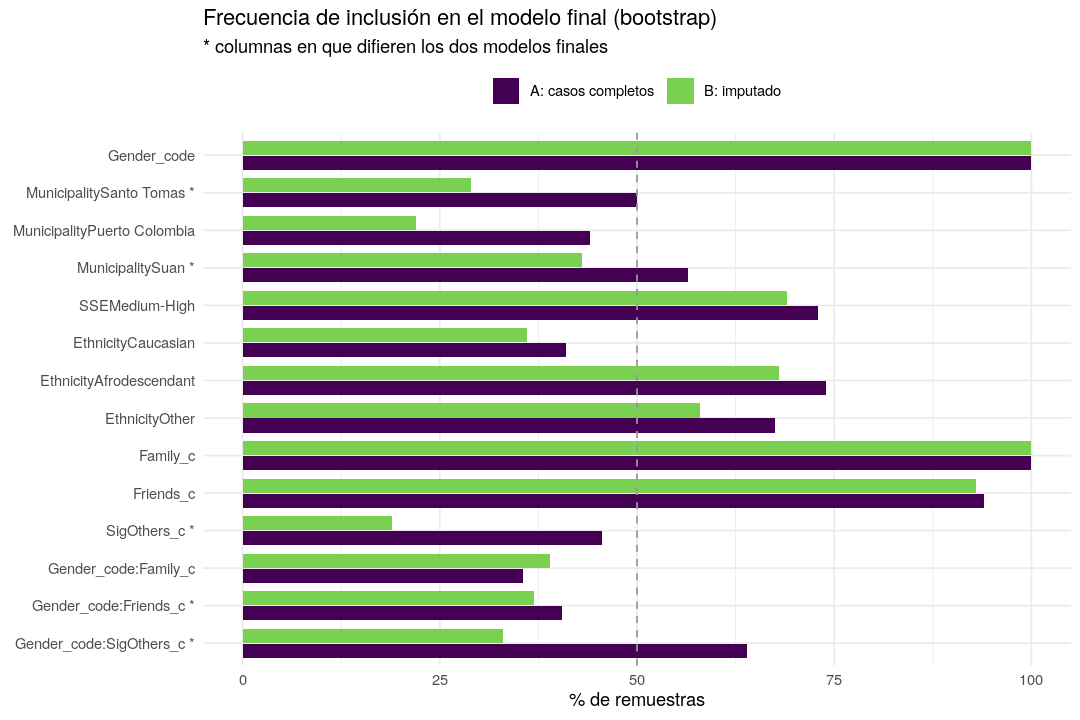

In [17]:
options(repr.plot.width = 9, repr.plot.height = 6)

frec %>%
  mutate(Modelo = recode(Modelo, A = "A: casos completos", B = "B: imputado"),
         Columna = factor(ifelse(Columna %in% destacar, paste0(Columna, " *"), Columna),
                          levels = rev(ifelse(columnas %in% destacar, paste0(columnas, " *"), columnas)))) %>%
  ggplot(aes(x = incl, y = Columna, fill = Modelo)) +
  geom_col(position = position_dodge(width = 0.8), width = 0.75) +
  geom_vline(xintercept = 50, linetype = "dashed", color = "grey60") +
  scale_fill_manual(values = c(col_morado, col_verde)) +
  scale_x_continuous(limits = c(0, 100)) +
  labs(title = "Frecuencia de inclusión en el modelo final (bootstrap)",
       subtitle = "* columnas en que difieren los dos modelos finales",
       x = "% de remuestras", y = NULL, fill = NULL) +
  theme_minimal() +
  theme(legend.position = "top")

## *Guardado*

- `outputs/tables/bootstrap_coeficientes.csv`: coeficientes e IC de la parte 1.
- `outputs/tables/bootstrap_seleccion.csv`: frecuencias de inclusión de la parte 2.

Las remuestras quedan en `outputs/models/bootstrap_*.rds`.

In [18]:
dir.create("outputs/tables", showWarnings = FALSE, recursive = TRUE)

bind_rows(ic_a %>% mutate(modelo = "A"), ic_b %>% mutate(modelo = "B"),
          ic_dif %>% transmute(term, estimate = dif, lo, hi, modelo = "A - B")) %>%
  select(modelo, term, estimate, std_error, lo, hi) %>%
  write_csv("outputs/tables/bootstrap_coeficientes.csv")
write_csv(frec, "outputs/tables/bootstrap_seleccion.csv")

cat("outputs/tables/bootstrap_coeficientes.csv\noutputs/tables/bootstrap_seleccion.csv\n")

outputs/tables/bootstrap_coeficientes.csv
outputs/tables/bootstrap_seleccion.csv
